## 1. Install

In [1]:
!pip -q install ultralytics kagglehub opencv-python-headless

## 2. Kaggle token

In [2]:
import os
TOKEN = "PASTE_YOUR_TOKEN_HERE"
os.environ["KAGGLE_API_TOKEN"] = TOKEN
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
with open(os.path.expanduser("~/.kaggle/access_token"), "w") as f:
    f.write(TOKEN)
print("Kaggle token saved")

Kaggle token saved


## 3. Download dataset

In [3]:
import kagglehub
DATA = kagglehub.dataset_download("mohamedmustafa/real-life-violence-situations-dataset")
print(DATA)

Using Colab cache for faster access to the 'real-life-violence-situations-dataset' dataset.
/kaggle/input/real-life-violence-situations-dataset


## 4. Videos to photos (no duplicates)

In [4]:
import random, shutil, cv2

FIGHT_NAMES = {"violence", "fight"}
NORMAL_NAMES = {"nonviolence", "non_violence", "non-violence", "normal"}
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv"}
OUT, FRAMES_PER_VIDEO, IMG = "frames_dataset", 8, 224

def find_videos(root):
    found, seen = {"fight": [], "normal": []}, set()
    for dirpath, _, names in sorted(os.walk(root)):
        folder = os.path.basename(dirpath).lower()
        label = "fight" if folder in FIGHT_NAMES else "normal" if folder in NORMAL_NAMES else None
        if not label:
            continue
        for n in sorted(names):
            path = os.path.join(dirpath, n)
            key = (label, n.lower(), os.path.getsize(path))  # the dataset has every video twice
            if os.path.splitext(n)[1].lower() in VIDEO_EXT and key not in seen:
                seen.add(key)
                found[label].append(path)
    return found

def extract_frames(video, out_dir):
    cap = cv2.VideoCapture(video)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    saved = 0
    if total > 0:
        start, end = int(total * 0.1), max(int(total * 0.9), 1)
        step = max((end - start) // FRAMES_PER_VIDEO, 1)
        base = os.path.splitext(os.path.basename(video))[0]
        for i in range(FRAMES_PER_VIDEO):
            cap.set(cv2.CAP_PROP_POS_FRAMES, start + i * step)
            ok, frame = cap.read()
            if ok:
                cv2.imwrite(os.path.join(out_dir, f"{base}_{i}.jpg"), cv2.resize(frame, (IMG, IMG)))
                saved += 1
    cap.release()
    return saved

videos = find_videos(DATA)
print(f"Found {len(videos['fight'])} fight and {len(videos['normal'])} normal videos (should be 1000 each)")

random.seed(42)
shutil.rmtree(OUT, ignore_errors=True)
test_videos = {}
for label, vids in videos.items():
    random.shuffle(vids)
    cut = int(len(vids) * 0.8)
    test_videos[label] = vids[cut:]
    for split, subset in (("train", vids[:cut]), ("val", vids[cut:])):
        out_dir = os.path.join(OUT, split, label)
        os.makedirs(out_dir, exist_ok=True)
        n = sum(extract_frames(v, out_dir) for v in subset)
        print(f"  {split}/{label}: {n} photos from {len(subset)} videos")

Found 1000 fight and 1000 normal videos (should be 1000 each)
  train/fight: 6400 photos from 800 videos
  val/fight: 1600 photos from 200 videos
  train/normal: 6400 photos from 800 videos
  val/normal: 1600 photos from 200 videos


## 5. Train

In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n-cls.pt")
results = model.train(data=OUT, epochs=15, imgsz=IMG, batch=64, patience=5,
                      project="runs", name="fight", exist_ok=True)
shutil.copy(os.path.join(str(results.save_dir), "weights", "best.pt"), "fight_cls.pt")
print("Saved fight_cls.pt", YOLO("fight_cls.pt").names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=frames_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv

## 6. Accuracy on unseen videos

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,437,442 parameters, 0 gradients, 3.3 GFLOPs
train: /content/frames_dataset/train... found 12800 images in 2 classes ✅ 
val: /content/frames_dataset/val... found 3200 images in 2 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 824.9±307.3 MB/s, size: 13.0 KB)
val: Scanning /content/frames_dataset/val... 3200 images, 0 corrupt: 100% ━━━━━━━━━━━━ 3200/3200 894.8Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 200/200 33.3it/s 6.0s
                   all      0.975          1
Speed: 0.1ms preprocess, 0.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Accuracy on unseen photos: 97.5%


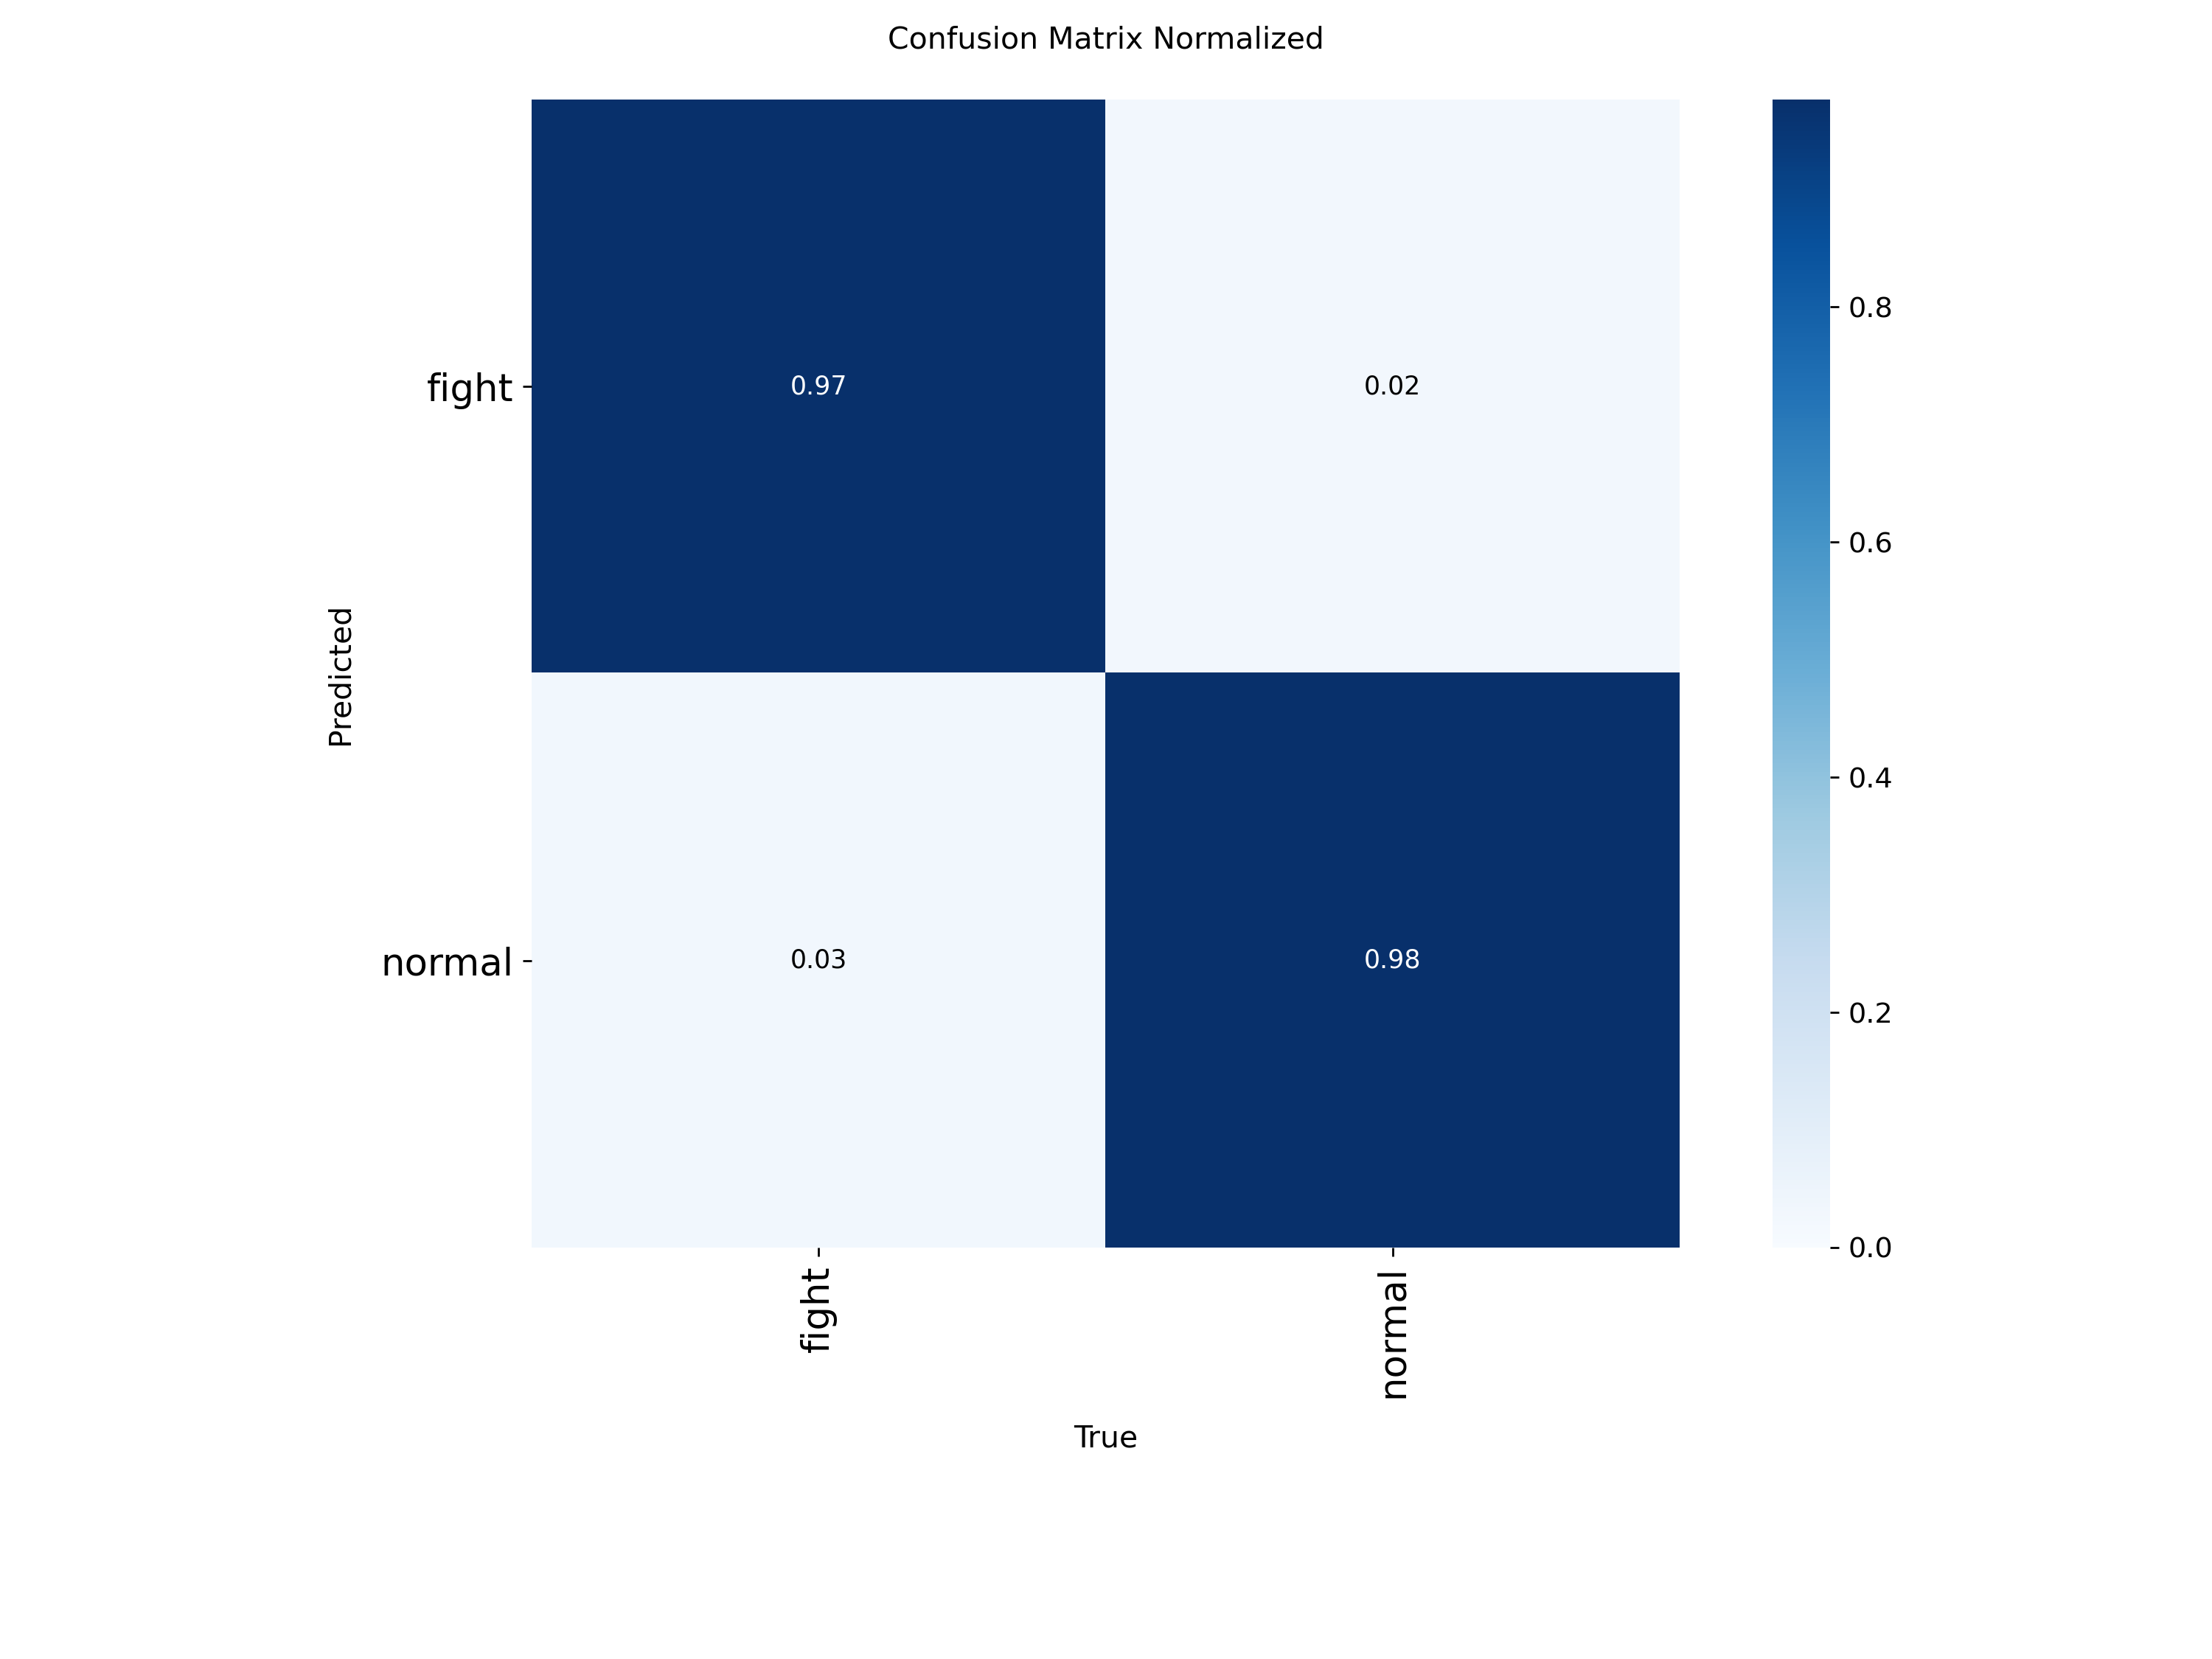

In [6]:
from IPython.display import Image, display

metrics = YOLO("fight_cls.pt").val(data=OUT, imgsz=IMG, split="val", verbose=False)
print(f"Accuracy on unseen photos: {metrics.top1 * 100:.1f}%")
cm = os.path.join(str(results.save_dir), "confusion_matrix_normalized.png")
if os.path.exists(cm):
    display(Image(cm, width=450))

## 7. Test like the bus (1 photo per second, 3 in a row = alert)

In [7]:
clf = YOLO("fight_cls.pt")
FIGHT_IDX = next(i for i, n in clf.names.items() if n == "fight")

def check_video(path, threshold=0.6, streak_needed=3):
    cap = cv2.VideoCapture(path)
    fps = int(cap.get(cv2.CAP_PROP_FPS) or 25)
    scores, i = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % fps == 0:
            r = clf(frame, verbose=False)[0]
            scores.append(float(r.probs.data[FIGHT_IDX]))
        i += 1
    cap.release()
    streak = best = 0
    for s in scores:
        streak = streak + 1 if s >= threshold else 0
        best = max(best, streak)
    return scores, best >= streak_needed

correct = total = 0
for label in ("fight", "normal"):
    for v in test_videos[label]:
        scores, alert = check_video(v)
        correct += alert == (label == "fight")
        total += 1
print(f"Unseen videos correct: {correct}/{total} ({correct / total * 100:.1f}%)")

Unseen videos correct: 392/400 (98.0%)


## 8. Download

In [8]:
import zipfile
from google.colab import files

with zipfile.ZipFile("demo_videos.zip", "w") as z:
    for label in ("fight", "normal"):
        for n, v in enumerate(test_videos[label][:4], 1):
            z.write(v, f"demo_videos/{label}_{n}{os.path.splitext(v)[1]}")

files.download("fight_cls.pt")
files.download("demo_videos.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>